---
layout: post
title: Group theory with pizza
description: "it's yummy and mathematical"
date: 2026-05-09
author: Yair Mau
toc: true
format:
  html:
    code-fold: true
    code-summary: "Show the code"
image: thirds.png
categories: [math]
---

The tutorial below is heavily inspired by the following two videos, which are both excellent and worth watching. [video 1](https://www.youtube.com/watch?v=_BrFKp-U8GI){target="_blank"} and [video 2](https://www.youtube.com/watch?v=1XsXRUsNEC4){target="_blank"}.

## the problem

A pizza place sells pizzas divided into 6 slices. Costumers can choose three kinds of toppings: cheese (shown in yellow), pepperoni (red) and mushrooms (brown). If the costumer tells that they want 3 cheese slices, 2 pepperoni and 1 mushroom, the pizza place could deliver them the following:

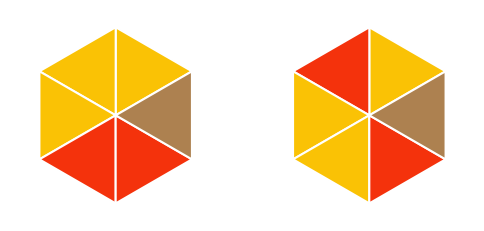

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(6, 6))
rng = np.random.default_rng(seed=0)
draw_hex_pizza(ax[0], [0, 0, 0, 1, 1, 2])
draw_hex_pizza(ax[1], [0, 1, 0, 0, 1, 2])

The right option is absurd

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
rng = np.random.default_rng(seed=0)
pizza = rng.integers(0, 3, size=(6))  # Random toppings for each pizza slice

draw_hex_pizza(ax[0], [])

In [31]:
# draw a 6-slice pizza with 3 possible toppings
def draw_hex_pizza(ax, toppings, radius=1.0):
    if len(toppings) != 6 or any(t not in (0, 1, 2) for t in toppings):
        raise ValueError("toppings must be a list of 6 elements, each in {0, 1, 2}.")

    color_map = {
        0: "xkcd:goldenrod",
        1: "xkcd:vermillion",
        2: "xkcd:light brown",
    }

    angles = np.linspace(0, 2 * np.pi, 7) + np.pi / 6  # Offset to align slices
    vx = radius * np.cos(angles[:-1])
    vy = radius * np.sin(angles[:-1])

    # Draw 6 triangular slices
    for i, t in enumerate(toppings):
        x = [0, vx[i], vx[(i + 1) % 6]]
        y = [0, vy[i], vy[(i + 1) % 6]]
        ax.fill(x, y, facecolor=color_map[t], edgecolor="white", linewidth=1.5)

    # Outer hexagon border
    # ax.plot(np.r_[vx, vx[0]], np.r_[vy, vy[0]], color="black", linewidth=2)

    ax.set_aspect("equal")
    ax.set_xlim(-1.2 * radius, 1.2 * radius)
    ax.set_ylim(-1.2 * radius, 1.2 * radius)
    ax.axis("off")

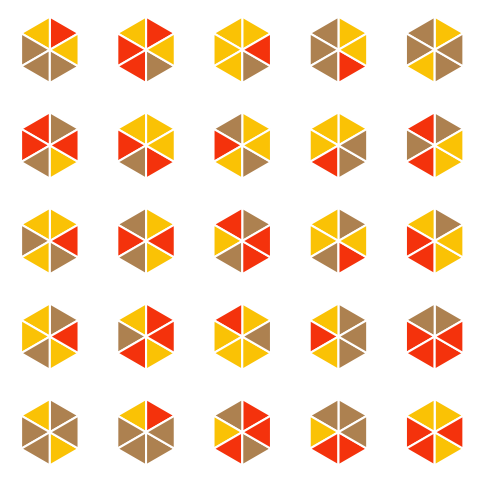

In [27]:
fig, ax = plt.subplots(5, 5, figsize=(6, 6))

ax = ax.flatten()

rng = np.random.default_rng(seed=42)
pizzas = rng.integers(0, 3, size=(5, 5, 6))  # Random toppings for each pizza slice

for i in range(5):
    for j in range(5):
        draw_hex_pizza(ax[i * 5 + j], pizzas[i, j])




In [1]:
import numpy as np
import matplotlib.pyplot as plt

def plot_single_graph(ax, edge_list, title=""):
    """Plots a minimalist, clean graph on a fixed circular layout."""
    # Compute coordinates
    theta = np.linspace(0, 2*np.pi, 6, endpoint=False)
    x = np.cos(theta)
    y = np.sin(theta)
    
    # Draw edges
    for edge in edge_list:
        u, v = edge
        ax.plot([x[u], x[v]], [y[u], y[v]], color='#2c3e50', linewidth=2, zorder=1)
        
    # Draw nodes
    ax.scatter(x, y, color='white', edgecolor='#2c3e50', s=400, linewidths=2, zorder=2)
    
    # Add small text labels inside nodes
    for i in range(6):
        ax.text(x[i], y[i], str(i), color='#2c3e50', ha='center', va='center', 
                fontsize=10, fontweight='bold', zorder=3)
        
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect('equal')
    ax.axis('off')
    if title:
        ax.set_title(title, fontsize=12, color='#2c3e50')

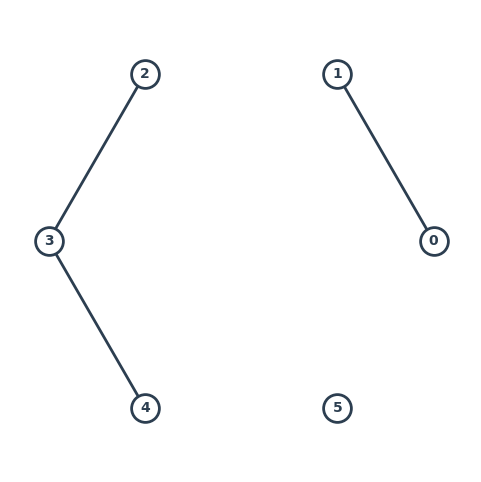

In [8]:
fig, ax = plt.subplots(figsize=(6, 6))
plot_single_graph(ax, ((0, 1), (2, 3), (3, 4),))